# Bisiklet Kiralama Talebi: Tek Bir Tabloyu Keşfetmek

Her hücre tek bir iş yapar. Yukarıdan aşağıya sırayla çalıştırın.

Bu defterde kullanılan tablo `day.csv`: Washington D.C.'deki Capital Bikeshare sisteminin 2011–2012 yıllarına ait günlük kiralama sayıları ile o günlerin hava durumu ve takvim bilgileri. Her satır bir gün. İş, bir model ya da panel kurulmadan önce tabloyu betimlemek.

Temel soru: **Hava durumu, mevsimsel ve zamansal faktörler bisiklet kiralama talebini nasıl etkiliyor?**

In [4]:
%matplotlib inline
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")

## 1. Veriyi açma

`read_csv`, `day.csv` dosyasını bir tabloya yükler.

`shape` satır ve sütun sayısını verir.

`dtypes` her sütunun veri türünü gösterir.

`head()` ise veri setinin ilk beş satırını görmemizi sağlar.

Bu aşamada veriyi yalnızca inceliyoruz. Henüz hiçbir değeri değiştirmiyoruz.

In [5]:
df = pd.read_csv("data/day.csv")

print(df.shape)

print(df.dtypes)

df.head()

(731, 16)
instant         int64
dteday         object
season          int64
yr              int64
mnth            int64
holiday         int64
weekday         int64
workingday      int64
weathersit      int64
temp          float64
atemp         float64
hum           float64
windspeed     float64
casual          int64
registered      int64
cnt             int64
dtype: object


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


## 2. Yapıyı kontrol etme

Analizden önce tablonun neye izin verdiğine bakılır: hiçbir hücre boş mu, aynı satır iki kez yazılmış mı, hiçbir değer mümkün olan aralığın dışında mı?

`isna().sum()` her sütundaki boş hücre sayısını verir. `duplicated().sum()` tekrar eden satırları sayar. `temp`, `atemp`, `hum` ve `windspeed` 0 ile 1 arasına ölçeklendiği için bu aralığın dışında değer olmamalıdır.

Ayrıca bu veri setine özgü olarak toplam kiralama sayısının `casual + registered` toplamına eşit olup olmadığı, sıfır değerler ve kategorik değişkenlerde beklenmeyen kodlar kontrol edilir.

Bu aşamada yalnızca kontrol yapılır; hiçbir değer değiştirilmez veya silinmez.

In [6]:
print(df.isna().sum())
print("duplicate rows:", df.duplicated().sum())

weather = ["temp", "atemp", "hum", "windspeed"]

print("outside 0-1:")
print(((df[weather] < 0) | (df[weather] > 1)).sum())

instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64
duplicate rows: 0
outside 0-1:
temp         0
atemp        0
hum          0
windspeed    0
dtype: int64


In [7]:
print("cnt != casual + registered:",
      (df["cnt"] != df["casual"] + df["registered"]).sum())

print("zero values:")
print((df[weather + ["casual", "registered", "cnt"]] == 0).sum())

for col in ["season", "yr", "mnth", "holiday", "weekday", "workingday", "weathersit"]:
    print(col, sorted(df[col].unique().tolist()))

cnt != casual + registered: 0
zero values:
temp          0
atemp         0
hum           1
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64
season [1, 2, 3, 4]
yr [0, 1]
mnth [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
holiday [0, 1]
weekday [0, 1, 2, 3, 4, 5, 6]
workingday [0, 1]
weathersit [1, 2, 3]


In [8]:
gap = (df["atemp"] - df["temp"]).abs()

df.assign(gap=gap).nlargest(
    5, "gap"
)[["dteday", "temp", "atemp", "gap"]]

,dteday,temp,atemp,gap
594,2012-08-17,0.723333,0.242400,0.480933
265,2011-09-23,0.609167,0.522125,0.087042
207,2011-07-27,0.775000,0.690667,0.084333
221,2011-08-10,0.766667,0.684983,0.081684
548,2012-07-02,0.781667,0.702038,0.079629


## 3. Gerekçeli değişiklikler

Yalnızca gerekçelendirebildiğimiz değişikliği yaparız. Bölüm 2'de iki şüpheli gözlem bulundu: nemi sıfır olan tek gün ve `temp` ile `atemp` arasındaki farkın alışılmadık büyük olduğu 2012-08-17. Şüpheli olmak hatalı olmakla aynı şey değildir. Bu yüzden önce her iki satırı, bir önceki ve bir sonraki günle birlikte yan yana koyarız: değer komşularına göre makul mü, yoksa tek başına mı duruyor?

Kanıtı gördükten sonra neyin değişeceğine karar verilir ve değişiklik nedeniyle birlikte bu bölümde yazılır. Hiçbir satır silinmez.

Aşağıdaki iki hücre yalnızca bakar, hiçbir şeyi değiştirmez.

In [9]:
context = ["dteday", "workingday", "weathersit", "temp", "atemp", "hum", "windspeed", "cnt"]
i = df.index[df["hum"] == 0][0]
df.loc[i - 1 : i + 1, context]

,dteday,workingday,weathersit,temp,atemp,hum,windspeed,cnt
67,2011-03-09,1,2,0.295833,0.286608,0.775417,0.220150,1891
68,2011-03-10,1,3,0.389091,0.385668,0.000000,0.261877,623
69,2011-03-11,1,2,0.316522,0.305000,0.649565,0.232970,1977


In [10]:
j = df.index[df["dteday"] == "2012-08-17"][0]
df.loc[j - 1 : j + 1, context]

,dteday,workingday,weathersit,temp,atemp,hum,windspeed,cnt
593,2012-08-16,1,1,0.719167,0.654688,0.519167,0.141796,7605
594,2012-08-17,1,1,0.723333,0.242400,0.570833,0.231354,7148
595,2012-08-18,0,1,0.678333,0.618071,0.603333,0.177867,7865


**Karar.** Bu bölümde bakılan iki şüpheli gözlemde yalnızca ilgili hücreler eksik (`pd.NA`) yapılır: 2011-03-10 tarihindeki `hum` ve 2012-08-17 tarihindeki `atemp`.

Neden satırın tamamı değil, yalnızca hücre? İki satırda da sorun tek bir değişkendedir. Aynı satırların diğer değerleri, özellikle `cnt`, komşu günlerle çelişmez. Satırı silmek bu geçerli görünen değerleri de atmak olurdu.

Neden değer olduğu gibi bırakılmıyor? Sıfır nem ve tutarsız hissedilen sıcaklık, dağılımı ve korelasyonları tek başına bozabilir. Eksik hücreler ortalama ya da medyanla doldurulmaz, çünkü uydurulmuş bir değer veride olmayan bir bilgiyi varmış gibi gösterir. pandas ortalama ve korelasyon gibi hesaplarda eksik hücreleri otomatik atlar: bu iki değişken 730 gözlemle hesaplanır.

Bu iki gözlem hata olarak kanıtlanmış değil, "şüpheli/tutarsız gözlem"dir ve nedenleri bilinmiyor. Değişiklik yalnızca bellekteki `df` üzerinde yapılır, `day.csv` dosyası olduğu gibi kalır. Hiçbir satır silinmez, `cnt` dahil diğer bütün sütunlar korunur.

In [11]:
hum_day = df["dteday"] == "2011-03-10"
atemp_day = df["dteday"] == "2012-08-17"
df.loc[hum_day, "hum"] = pd.NA
df.loc[atemp_day, "atemp"] = pd.NA

In [12]:
print(df.shape)
print(df[["hum", "atemp"]].isna().sum())
print("missing cells in total", int(df.isna().sum().sum()))

(731, 16)
hum      1
atemp    1
dtype: int64
missing cells in total 2


In [13]:
df.loc[hum_day | atemp_day, ["dteday", "temp", "atemp", "hum", "cnt"]]

,dteday,temp,atemp,hum,cnt
68,2011-03-10,0.389091,0.385668,NaN,623
594,2012-08-17,0.723333,NaN,0.570833,7148


## 4. Tek bir kategorinin sayıları: hava durumu (`weathersit`)

`weathersit` günün hava durumunu kodlar: 1 açık ya da az bulutlu, 2 sisli/puslu ve bulutlu, 3 hafif kar ya da hafif yağmur. Bölüm 2'de günlük veride yalnızca bu üç kodu gördük. Kodların doğal bir sırası vardır ama aralarındaki fark eşit olmak zorunda değildir: "ortalama hava durumu 1,6" bir anlam taşımaz. Bu yüzden her kodun frekansına bakarız, yani o koda sahip gün sayısına. En büyük frekans moddur. Bu sayılar gün sayısıdır, kiralama sayısı değil.

Oran, her frekansı bilinen etiketlerin toplamına böler (`p`), yüzde bunun 100 ile çarpılmış halidir. Farklı büyüklükteki grupları karşılaştırmayı kolaylaştırır. Bu sütunda eksik değer olmadığı için `dropna` hiçbir şeyi değiştirmez, ama hocanın kalıbını koruyoruz.

Bar grafiğinde her kategori için bir çubuk vardır, çubuğun uzunluğu frekansa eşittir ve eksen sıfırdan başlar. Hocanın örneğinde adlar sırasız olduğu için çubuklar büyüklüğe göre sıralanıyordu. Burada kodların doğal bir sırası olduğundan 1, 2, 3 sırasını koruyoruz. Kodlar henüz isimlere çevrilmedi, ham hâliyle gösteriliyor.

In [14]:
print(df["weathersit"].value_counts(dropna=False).sort_index())
known = df["weathersit"].dropna()
counts = known.value_counts().sort_index()
pd.DataFrame({
    "f": counts,
    "p": counts / counts.sum(),
    "percent": (100 * counts / counts.sum()).round(1),
})

weathersit
1    463
2    247
3     21
Name: count, dtype: int64


,f,p,percent
weathersit,,,
1,463,0.633379,63.3
2,247,0.337893,33.8
3,21,0.028728,2.9


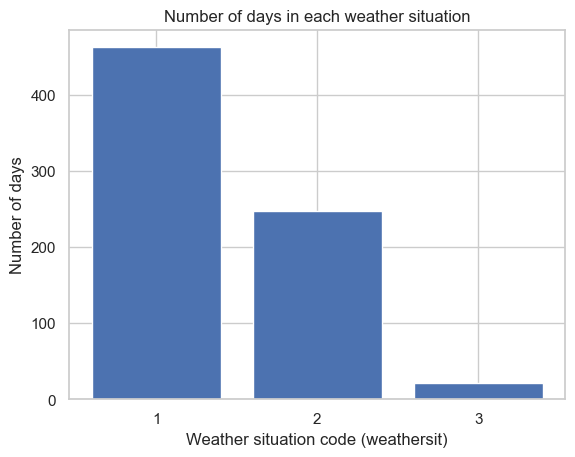

In [15]:
counts = df["weathersit"].value_counts().sort_index()
fig, ax = plt.subplots()
ax.bar(counts.index.astype(str), counts.values)
ax.set_xlabel("Weather situation code (weathersit)")
ax.set_ylabel("Number of days")
ax.set_title("Number of days in each weather situation")
plt.show()

## 4 (devam). Tek bir kategorinin sayıları: mevsim (`season`)

Aynı yöntemi bu kez `season` için uygularız: her kodun kaç günde göründüğü (frekans), oranı ve yüzdesi, ardından bar grafiği. Mevsim kodu 1'den 4'e sıralıdır ve döngüseldir (4'ten sonra yeniden 1 gelir); "ortalama mevsim kodu" bir anlam taşımaz. Frekans gün sayısıdır, kiralama sayısı değil.

**Etiket uyarısı.** Veri setinin iki kaynağı kodların anlamını farklı veriyor: UCI sayfasında 1 kış, 2 ilkbahar, 3 yaz, 4 sonbahar; `Readme.txt` dosyasında ise 1 ilkbahar, 2 yaz, 3 sonbahar, 4 kış yazıyor. İkisi birden doğru olamaz. Bu yüzden bu bölümde kodlara isim vermiyoruz, ham kodlarla (1, 2, 3, 4) çalışıyoruz. Doğru etiket, tarih sütunu (`dteday`) dönüştürüldükten sonra kodların hangi tarihlere denk geldiği kontrol edilerek ve kaynak belirtilerek seçilecek.

Çubuk grafiğinde kodların doğal sırası (1, 2, 3, 4) korunur. Hocanın örneğinde adlar sırasızdı ve çubuklar büyüklüğe göre sıralanıyordu; burada sıra bilgisi anlamlı olduğu için sıralamıyoruz.

In [16]:
print(df["season"].value_counts(dropna=False).sort_index())
known = df["season"].dropna()
counts = known.value_counts().sort_index()
pd.DataFrame({
    "f": counts,
    "p": counts / counts.sum(),
    "percent": (100 * counts / counts.sum()).round(1),
})

season
1    181
2    184
3    188
4    178
Name: count, dtype: int64


,f,p,percent
season,,,
1,181,0.247606,24.8
2,184,0.251710,25.2
3,188,0.257182,25.7
4,178,0.243502,24.4


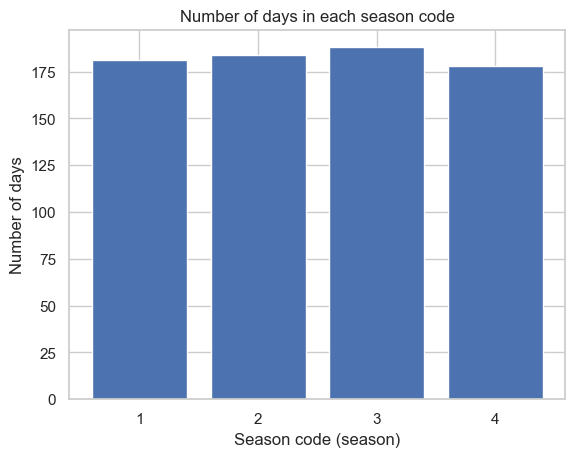

In [17]:
counts = df["season"].value_counts().sort_index()
fig, ax = plt.subplots()
ax.bar(counts.index.astype(str), counts.values)
ax.set_xlabel("Season code (season)")
ax.set_ylabel("Number of days")
ax.set_title("Number of days in each season code")
plt.show()

## 4 (devam). Tek bir kategorinin sayıları: çalışma günü (`workingday`)

`workingday` ikili bir koddur: veri dokümantasyonuna göre gün hafta sonu ya da resmi tatil değilse 1, aksi hâlde 0. Yani 0 grubu tek tür gün değil, hafta sonları ile tatillerin karışımıdır. İkili bir kodun ortalamasını yorumlamayız; bunun yerine her kodun frekansına (kaç gün) ve oranına bakarız. Frekans gün sayısıdır, kiralama sayısı değil.

Aynı kalıp uygulanır: frekans, oran (`p`), yüzde, ardından bar grafiği. Kodların doğal sırası 0, 1 olarak korunur. Kodlar ham hâliyle gösterilir, etiket eklenmez.

In [18]:
print(df["workingday"].value_counts(dropna=False).sort_index())
known = df["workingday"].dropna()
counts = known.value_counts().sort_index()
pd.DataFrame({
    "f": counts,
    "p": counts / counts.sum(),
    "percent": (100 * counts / counts.sum()).round(1),
})

workingday
0    231
1    500
Name: count, dtype: int64


,f,p,percent
workingday,,,
0,231,0.316005,31.6
1,500,0.683995,68.4


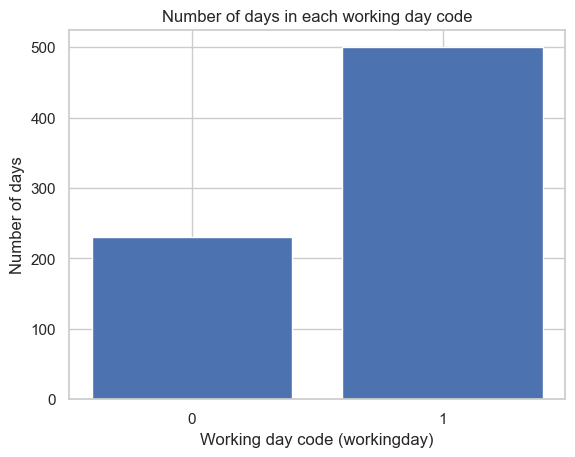

In [19]:
counts = df["workingday"].value_counts().sort_index()
fig, ax = plt.subplots()
ax.bar(counts.index.astype(str), counts.values)
ax.set_xlabel("Working day code (workingday)")
ax.set_ylabel("Number of days")
ax.set_title("Number of days in each working day code")
plt.show()

## 4 (devam). Tek bir kategorinin sayıları: haftanın günü (`weekday`)

`weekday`, haftanın gününü 0'dan 6'ya kadar kodlar. Veri dokümantasyonu yalnızca "haftanın günü" diyor, hangi kodun hangi güne karşılık geldiğini yazmıyor. Bunu tarih sütunu (`dteday`) dönüştürüldükten sonra tarihlerle karşılaştırarak doğrulayacağız. O zamana kadar ham kodlarla (0–6) çalışıyoruz ve "0 kodu", "1 kodu" gibi konuşuyoruz. Kodlar sıralı ve döngüseldir (6'dan sonra yeniden 0 gelir), "ortalama gün kodu" bir anlam taşımaz.

Aynı kalıp uygulanır: frekans, oran (`p`), yüzde, ardından bar grafiği. Frekans gün sayısıdır, kiralama sayısı değil. Tablo ardışık günlerden oluşuyorsa her haftada her koddan bir gün bulunacağı için frekansların birbirine çok yakın olması beklenir. Kodların doğal sırası (0, 1, …, 6) korunur ve kodlar ham hâliyle gösterilir.

In [20]:
print(df["weekday"].value_counts(dropna=False).sort_index())
known = df["weekday"].dropna()
counts = known.value_counts().sort_index()
pd.DataFrame({
    "f": counts,
    "p": counts / counts.sum(),
    "percent": (100 * counts / counts.sum()).round(1),
})

weekday
0    105
1    105
2    104
3    104
4    104
5    104
6    105
Name: count, dtype: int64


,f,p,percent
weekday,,,
0,105,0.143639,14.4
1,105,0.143639,14.4
2,104,0.142271,14.2
3,104,0.142271,14.2
4,104,0.142271,14.2
5,104,0.142271,14.2
6,105,0.143639,14.4


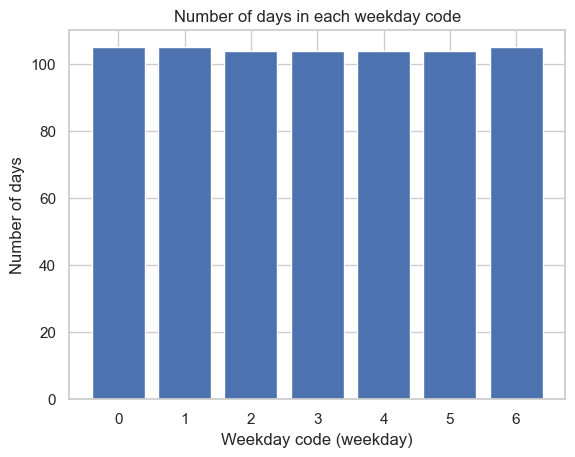

In [21]:
counts = df["weekday"].value_counts().sort_index()
fig, ax = plt.subplots()
ax.bar(counts.index.astype(str), counts.values)
ax.set_xlabel("Weekday code (weekday)")
ax.set_ylabel("Number of days")
ax.set_title("Number of days in each weekday code")
plt.show()

## 4 (devam). Tek bir kategorinin sayıları: ay (`mnth`)

`mnth`, ayı 1'den 12'ye kodlar. Kodlar sıralı ve döngüseldir (12'den sonra yeniden 1 gelir); "ortalama ay kodu" bir anlam taşımaz. Frekans gün sayısıdır, kiralama sayısı değil. Kodun takvimdeki ay numarasına karşılık geldiğini tarih sütunu (`dteday`) dönüştürüldükten sonra doğrulayacağız.

Önceki değişkenlerden önemli bir fark: aylar eşit uzunlukta değildir. Tablo 2011 ve 2012 yıllarını tam olarak kapsıyorsa 31 günlük bir ay iki yılda 62 gün, 30 günlük bir ay 60 gün içerir. Şubat ise 2011'de 28, 2012'de (artık yıl) 29 gün olduğundan 57 gün içerir. Bu yüzden frekansların eşit olması beklenmez; farklar ayların takvim uzunluğundan gelir ve veri hatası değildir.

Aynı kalıp uygulanır: frekans, oran (`p`), yüzde, ardından bar grafiği. Kodların doğal sırası (1, 2, …, 12) korunur ve kodlar ham hâliyle gösterilir.

In [22]:
print(df["mnth"].value_counts(dropna=False).sort_index())
known = df["mnth"].dropna()
counts = known.value_counts().sort_index()
pd.DataFrame({
    "f": counts,
    "p": counts / counts.sum(),
    "percent": (100 * counts / counts.sum()).round(1),
})

mnth
1     62
2     57
3     62
4     60
5     62
6     60
7     62
8     62
9     60
10    62
11    60
12    62
Name: count, dtype: int64


,f,p,percent
mnth,,,
1,62,0.084815,8.5
2,57,0.077975,7.8
3,62,0.084815,8.5
4,60,0.082079,8.2
5,62,0.084815,8.5
6,60,0.082079,8.2
7,62,0.084815,8.5
8,62,0.084815,8.5
9,60,0.082079,8.2


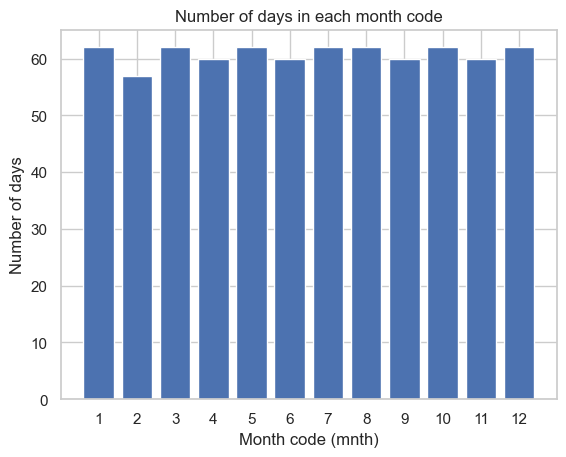

In [23]:
counts = df["mnth"].value_counts().sort_index()
fig, ax = plt.subplots()
ax.bar(counts.index.astype(str), counts.values)
ax.set_xlabel("Month code (mnth)")
ax.set_ylabel("Number of days")
ax.set_title("Number of days in each month code")
plt.show()

## 4 (devam). Tek bir kategorinin sayıları: tatil (`holiday`)

`holiday` ikili bir koddur: veri dokümantasyonuna göre günün tatil olup olmadığını gösterir ve bir tatil takviminden alınmıştır. 1 tatil günü, 0 tatil olmayan gündür. İkili bir kodun ortalamasını yorumlamayız; her kodun frekansına (kaç gün) ve oranına bakarız. Frekans gün sayısıdır, kiralama sayısı değil.

`holiday`, `workingday` ile aynı şey değildir. `workingday = 0` hem hafta sonlarını hem de tatilleri içerir, `holiday = 1` ise yalnızca tatil olarak kodlanan günleri gösterir; bir günün hafta sonuna denk gelmesi onu kendiliğinden `holiday = 1` yapmaz. İki sütun birbirinin yerine kullanılmaz.

Tatiller takvimde az sayıda gün tutar, bu yüzden iki grubun belirgin biçimde dengesiz olması beklenir. Aynı kalıp uygulanır: frekans, oran (`p`), yüzde, ardından bar grafiği. Kodların doğal sırası (0, 1) korunur ve kodlar ham hâliyle gösterilir.

In [24]:
print(df["holiday"].value_counts(dropna=False).sort_index())
known = df["holiday"].dropna()
counts = known.value_counts().sort_index()
pd.DataFrame({
    "f": counts,
    "p": counts / counts.sum(),
    "percent": (100 * counts / counts.sum()).round(1),
})

holiday
0    710
1     21
Name: count, dtype: int64


,f,p,percent
holiday,,,
0,710,0.971272,97.1
1,21,0.028728,2.9


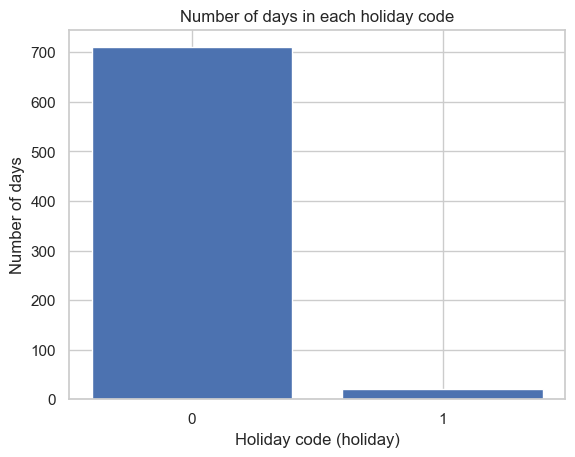

In [25]:
counts = df["holiday"].value_counts().sort_index()
fig, ax = plt.subplots()
ax.bar(counts.index.astype(str), counts.values)
ax.set_xlabel("Holiday code (holiday)")
ax.set_ylabel("Number of days")
ax.set_title("Number of days in each holiday code")
plt.show()

## 4 (devam). Tek bir kategorinin sayıları: yıl (`yr`)

`yr` ikili bir koddur: veri dokümantasyonuna göre 0 ilk yılı (2011), 1 ikinci yılı (2012) temsil eder. İkili bir kodun ortalamasını yorumlamayız; her kodun frekansına (kaç gün) ve oranına bakarız. Frekans gün sayısıdır, kiralama sayısı değil. Kodların yıllara karşılık geldiğini tarih sütunu (`dteday`) dönüştürüldükten sonra doğrulayacağız.

Tablo 2011 ve 2012 yıllarını tam olarak kapsıyorsa ilk yıl 365, ikinci yıl 366 gün içermelidir, çünkü 2012 artık yıldır. İki grubun tamamen eşit olması bu yüzden beklenmez; aralarında yalnızca 1 günlük fark beklenir. Bu sonuç yıl kodlarının dönemin yapısıyla uyumunu kontrol etmek için kullanılabilir, ancak tarih sütunu ayrıca doğrulanmadan tek başına kesin kanıt değildir.

Aynı kalıp uygulanır: frekans, oran (`p`), yüzde, ardından bar grafiği. Kodların doğal sırası (0, 1) korunur ve kodlar ham hâliyle gösterilir.

In [26]:
print(df["yr"].value_counts(dropna=False).sort_index())
known = df["yr"].dropna()
counts = known.value_counts().sort_index()
pd.DataFrame({
    "f": counts,
    "p": counts / counts.sum(),
    "percent": (100 * counts / counts.sum()).round(1),
})

yr
0    365
1    366
Name: count, dtype: int64


,f,p,percent
yr,,,
0,365,0.499316,49.9
1,366,0.500684,50.1


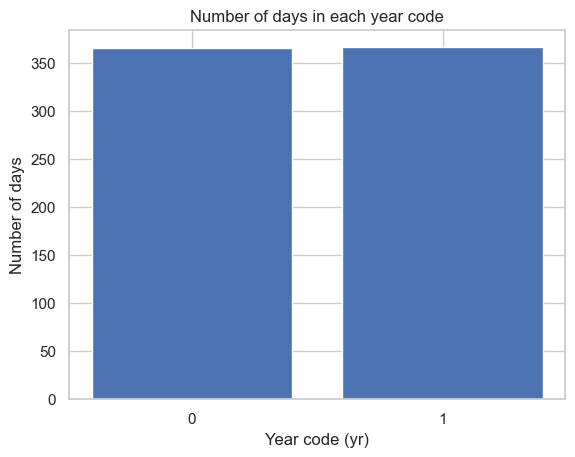

In [27]:
counts = df["yr"].value_counts().sort_index()
fig, ax = plt.subplots()
ax.bar(counts.index.astype(str), counts.values)
ax.set_xlabel("Year code (yr)")
ax.set_ylabel("Number of days")
ax.set_title("Number of days in each year code")
plt.show()

## 5. Tarih ve kod doğrulaması

Sayısal analize geçmeden önce, daha önce "ham kodlarla çalışıyoruz" diyerek açık bıraktığımız kontrolleri kapatırız. Bu bölüm yeni bir analiz değil, veri bütünlüğü ve kod doğrulamasıdır: `dteday` metin olarak okunduğu için önce tarihe çevirip tarihlerin kendisine, sonra bu tarihlere dayanarak `yr`, `mnth`, `weekday` ve `season` kodlarına bakarız. Dönüşüm yalnızca geçici bir seride (`dates`) yapılır; `df` değiştirilmez ve yeni sütun eklenmez.

Kontroller ve nedenleri:

- **Dönüşüm ve temel tarih kontrolleri:** Tarih metni gerçekten tarih olarak okunabiliyor mu (`NaT` yoksa evet)? İlk ve son tarih ne, tarihler sıralı mı, tekrar eden tarih var mı?
- **Ardışıklık:** Komşu tarihler arasındaki fark hep 1 gün mü? Fark 1'den büyükse gün atlanmış, 1'den küçükse sıra bozulmuş demektir. Frekans tabloları bunu tek başına kanıtlayamıyordu.
- **`yr` ve `mnth`:** Dokümantasyona göre `yr` 0 = 2011, 1 = 2012; `mnth` takvim ayıdır. Bunu tarihlerin gerçek yılı ve ayıyla karşılaştırırız.
- **`weekday`:** Dokümantasyon hangi kodun hangi güne denk geldiğini yazmıyor. Eşleşmeyi varsaymadan, kod ile gün adını çapraz tabloda yan yana koyup veriden okuruz.
- **`season`:** Etiketler konusunda UCI sayfası ve Readme çelişiyor. Burada yalnızca kodların hangi aylarda göründüğünü gösteririz; etiketi bu tablodan atamayız.

In [28]:
dates = pd.to_datetime(df["dteday"], errors="coerce")
print("failed conversions (NaT):", dates.isna().sum())
print("first date:", dates.min().date(), "| last date:", dates.max().date())
print("in chronological order:", dates.is_monotonic_increasing)
print("repeated dates:", dates.duplicated().sum())

failed conversions (NaT): 0
first date: 2011-01-01 | last date: 2012-12-31
in chronological order: True
repeated dates: 0


In [29]:
gaps = dates.diff().dt.days
print(gaps.value_counts(dropna=False))
print("transitions that are not 1 day:", (gaps.dropna() != 1).sum())
print("days from first to last date (inclusive):", (dates.max() - dates.min()).days + 1, "| rows:", len(df))

dteday
1.0    730
NaN      1
Name: count, dtype: int64
transitions that are not 1 day: 0
days from first to last date (inclusive): 731 | rows: 731


In [30]:
print("rows where yr does not match the real year:", (df["yr"] != dates.dt.year - 2011).sum())
pd.crosstab(df["yr"], dates.dt.year)

rows where yr does not match the real year: 0


dteday,2011,2012
yr,,
0,365,0
1,0,366


In [31]:
print("rows where mnth does not match the real month:", (df["mnth"] != dates.dt.month).sum())

rows where mnth does not match the real month: 0


In [32]:
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
table = pd.crosstab(df["weekday"], dates.dt.day_name())[day_order]
print(table.idxmax(axis=1))
print("non-zero cells:", int((table > 0).sum().sum()))
table

weekday
0       Sunday
1       Monday
2      Tuesday
3    Wednesday
4     Thursday
5       Friday
6     Saturday
dtype: object
non-zero cells: 7


dteday,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday
weekday,,,,,,,
0,0,0,0,0,0,0,105
1,105,0,0,0,0,0,0
2,0,104,0,0,0,0,0
3,0,0,104,0,0,0,0
4,0,0,0,104,0,0,0
5,0,0,0,0,104,0,0
6,0,0,0,0,0,105,0


In [33]:
pd.crosstab(df["mnth"], df["season"])

season,1,2,3,4
mnth,,,,
1,62,0,0,0
2,57,0,0,0
3,40,22,0,0
4,0,60,0,0
5,0,62,0,0
6,0,40,20,0
7,0,0,62,0
8,0,0,62,0
9,0,0,44,16


## 6. Sayısal değişkenler: temel özet ve merkez

Kategorik değişkenleri sayarak inceledik; sayısal değişkenlerde soru "ne kadar" olur. `describe` olağan sayıları tek tabloda toplar: kaç gözlem olduğu (`count`), ortalama (`mean`), standart sapma (`std`), en küçük ve en büyük değer (`min`, `max`) ve çeyrekler (`25%`, `50%`, `75%`). Ortalama her değeri kullandığı için uç bir değer onu çekebilir; medyan (`50%`) sıralı değerlerin ortasıdır ve yerinde kalır. Bu yüzden ikisini yan yana koyarız: aralarındaki fark dağılımın simetrik olup olmadığına dair yalnızca ilk bir izlenim verir, kesin bir sonuç değil.

Beş değişken: `cnt` bir günün toplam kiralama sayısıdır. `temp`, `atemp`, `hum` ve `windspeed` 0–1 arasına ölçeklenmiş (normalize) değerlerdir; gerçek birimleri (°C, %, rüzgâr birimi) değildir ve bu bölümde yalnızca bu ölçekte yorumlanır. `casual` ve `registered`, `cnt`'nin parçaları olduğu için bu özetin dışında bırakıldı.

`count`, eksik olmayan gözlem sayısıdır. Bölüm 3'te iki hücreyi eksik yaptığımız için `hum` ve `atemp` için 730, diğerleri için 731 beklenir. pandas eksik hücreleri bu hesaplarda otomatik dışarıda bırakır; hiçbir değer doldurulmaz ve `df` değişmez.

In [34]:
numeric = ["cnt", "temp", "atemp", "hum", "windspeed"]
df[numeric].describe().round(3)

,cnt,temp,atemp,hum,windspeed
count,731.000,731.000,730.000,730.000,731.000
mean,4504.349,0.495,0.475,0.629,0.190
std,1937.211,0.183,0.163,0.141,0.077
min,22.000,0.059,0.079,0.188,0.022
25%,3152.000,0.337,0.338,0.521,0.135
50%,4548.000,0.498,0.487,0.627,0.181
75%,5956.000,0.655,0.609,0.730,0.233
max,8714.000,0.862,0.841,0.972,0.507


In [35]:
pd.DataFrame({
    "mean": df[numeric].mean(),
    "median": df[numeric].median(),
    "mean - median": df[numeric].mean() - df[numeric].median(),
}).round(3)

,mean,median,mean - median
cnt,4504.349,4548.000,-43.651
temp,0.495,0.498,-0.003
atemp,0.475,0.487,-0.013
hum,0.629,0.627,0.002
windspeed,0.190,0.181,0.010
